# Validação Física: Pneus, Combustível e Clima — ApexSim

Este notebook compara o modelo físico (`sim/physics.py` e `sim/weather.py`) com os dados de telemetria real da F1 (2023–2024, 39.966 voltas limpas) e parâmetros da literatura.

**Resumo do que é dado/literatura vs. hipótese de modelagem:**
- **Pneus slicks (`soft`, `medium`, `hard`)**: coeficientes $k_{1,quad}$ e $k_{2,lin}$ ajustados aos dados reais; *cliff* e escala de aderência ($\tau = 3,0\text{ s}$) são hipóteses além da janela medida.
- **Combustível**: sensibilidade linear fixada em $0,03\text{ s/kg}$ (McLaren Applied).
- **Clima e chuva (`intermediate`, `wet`)**: degradação linear e ritmo base do *wet* ($+3,0\text{ s/volta}$) vêm da literatura; matriz de transição de Markov e penalidades fora da condição ideal são hipóteses para reproduzir o *crossover*.


In [1]:
%matplotlib inline
import json
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

backend_dir = Path("../../backend").resolve()
if str(backend_dir) not in sys.path:
    sys.path.insert(0, str(backend_dir))

from sim.physics import tyre_grip, tyre_time_loss, fuel_time_delta, TYRE_TABLE
from sim.weather import weather_time_delta, weather_grip_factor

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

data_path = Path("../../data/curvas_degradacao/curvas_degradacao.json")
with open(data_path, encoding="utf-8") as f:
    kaggle_data = json.load(f)

print(f"Dados carregados: {kaggle_data['meta']['n_voltas_limpas']} voltas limpas")
print(f"Compostos suportados: {list(TYRE_TABLE.keys())}")


Dados carregados: 39966 voltas limpas
Compostos suportados: ['soft', 'medium', 'hard', 'intermediate', 'wet']


## 1. Degradação e Aderência vs. Idade do Pneu (Pneus Slicks)

Comparação direta entre a perda de tempo medida na telemetria (com intervalo de confiança de 95%) e a curva gerada pelo modelo. Na linha inferior, a mesma perda de tempo é convertida em fator de aderência normalizado ($g = \frac{1}{1 + \Delta t / 3,0}$).

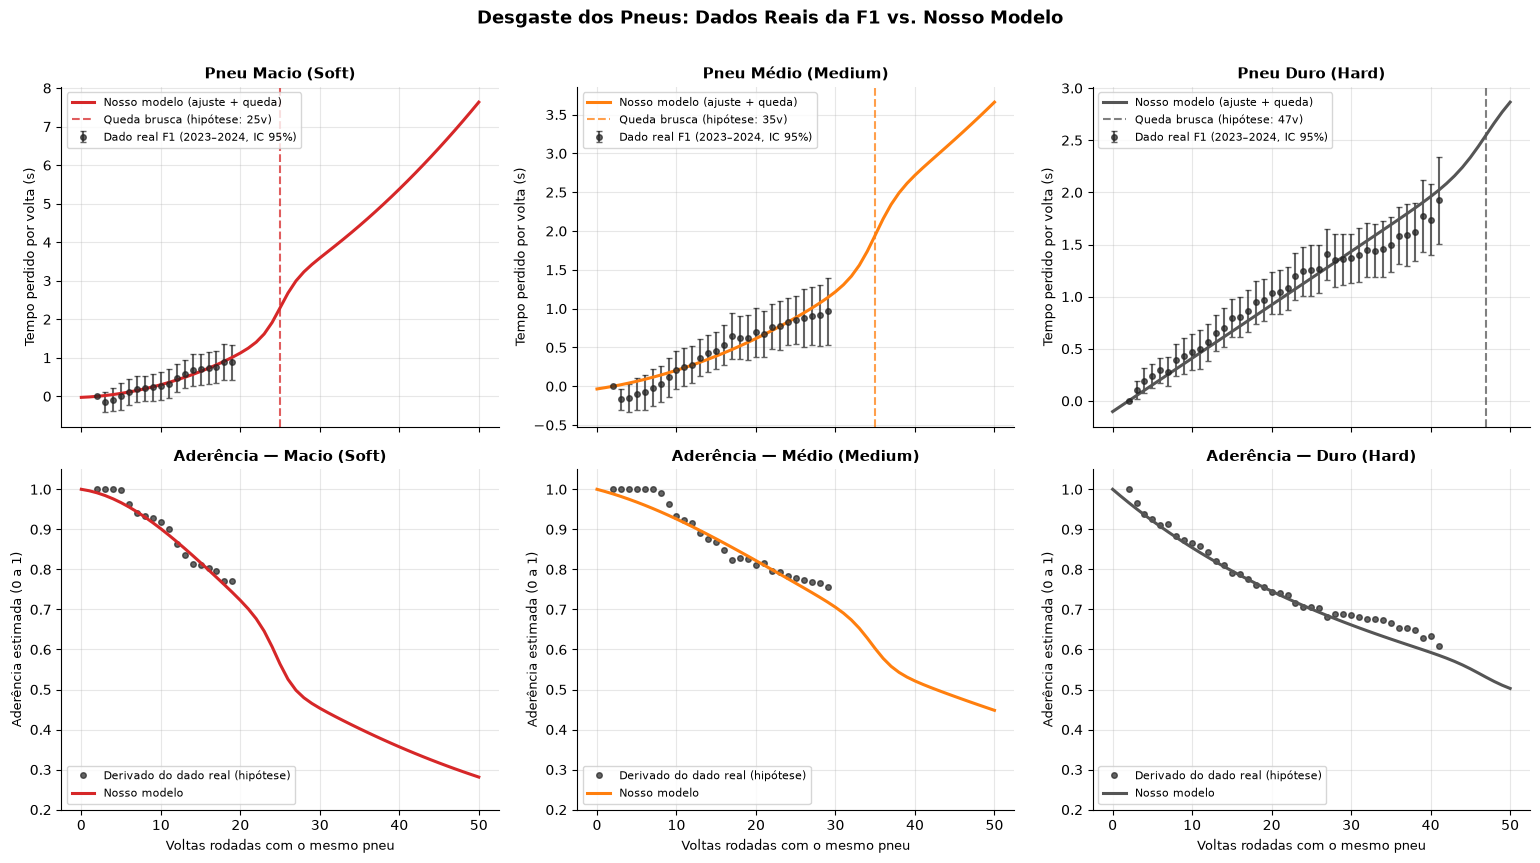

In [2]:
compounds = ["soft", "medium", "hard"]
comp_keys = {"soft": "SOFT", "medium": "MEDIUM", "hard": "HARD"}
comp_labels = {"soft": "Macio (Soft)", "medium": "Médio (Medium)", "hard": "Duro (Hard)"}
colors = {"soft": "#d62728", "medium": "#ff7f0e", "hard": "#555555"}

fig, axes = plt.subplots(2, 3, figsize=(15.5, 8.5), sharex=True)
ages_model = np.arange(0, 51)

for idx, c in enumerate(compounds):
    c_key = comp_keys[c]
    c_lbl = comp_labels[c]
    curva_real = kaggle_data["compostos"][c_key]["curva"]
    idades_reais = [pt["idade"] for pt in curva_real]
    perdas_reais = [pt["perda_s"] for pt in curva_real]
    erros_reais = [pt["erro_padrao_s"] for pt in curva_real]
    grip_proj_real = [1.0 / (1.0 + max(0.0, pt["perda_s"]) / 3.0) for pt in curva_real]

    perdas_modelo = [tyre_time_loss(c, a) - tyre_time_loss(c, 2) for a in ages_model]
    grip_modelo = [tyre_grip(c, a) for a in ages_model]

    ax_loss = axes[0, idx]
    ax_loss.errorbar(
        idades_reais,
        perdas_reais,
        yerr=[1.96 * e for e in erros_reais],
        fmt="o",
        color="#222222",
        alpha=0.7,
        markersize=4,
        capsize=2.5,
        label="Dado real F1 (2023–2024, IC 95%)",
    )
    ax_loss.plot(ages_model, perdas_modelo, "-", color=colors[c], lw=2.2, label="Nosso modelo (ajuste + queda)")
    ax_loss.axvline(
        TYRE_TABLE[c].cliff_age,
        color=colors[c],
        ls="--",
        alpha=0.75,
        lw=1.5,
        label=f"Queda brusca (hipótese: {TYRE_TABLE[c].cliff_age:.0f}v)",
    )
    ax_loss.set_title(f"Pneu {c_lbl}", fontsize=11, fontweight="bold")
    ax_loss.set_ylabel("Tempo perdido por volta (s)", fontsize=9.5)
    ax_loss.grid(alpha=0.3)
    ax_loss.legend(fontsize=8.2, loc="upper left", frameon=True)

    ax_grip = axes[1, idx]
    ax_grip.plot(idades_reais, grip_proj_real, "o", color="#222222", alpha=0.7, markersize=4, label="Derivado do dado real (hipótese)")
    ax_grip.plot(ages_model, grip_modelo, "-", color=colors[c], lw=2.2, label="Nosso modelo")
    ax_grip.set_title(f"Aderência — {c_lbl}", fontsize=11, fontweight="bold")
    ax_grip.set_xlabel("Voltas rodadas com o mesmo pneu", fontsize=9.5)
    ax_grip.set_ylabel("Aderência estimada (0 a 1)", fontsize=9.5)
    ax_grip.set_ylim(0.2, 1.05)
    ax_grip.grid(alpha=0.3)
    ax_grip.legend(fontsize=8.2, loc="lower left", frameon=True)

fig.suptitle("Desgaste dos Pneus: Dados Reais da F1 vs. Nosso Modelo", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("validacao_pneus_grip.png", dpi=130, bbox_inches="tight")
plt.show()


## 2. Verificação de Vida Útil e Ordenação Pós-Cliff

In [3]:
age_check = 38
losses = {c: tyre_time_loss(c, age_check) for c in compounds}
print(f"Perda de tempo na volta {age_check}:")
for c, v in losses.items():
    print(f"  {c.capitalize():>6}: {v:.3f} s (cliff em {TYRE_TABLE[c].cliff_age:.0f} voltas)")

assert TYRE_TABLE["soft"].cliff_age < TYRE_TABLE["medium"].cliff_age < TYRE_TABLE["hard"].cliff_age
assert losses["soft"] > losses["medium"] > losses["hard"]


Perda de tempo na volta 38:
    Soft: 5.011 s (cliff em 25 voltas)
  Medium: 2.527 s (cliff em 35 voltas)
    Hard: 1.950 s (cliff em 47 voltas)


## 3. Acréscimo de Tempo vs. Massa de Combustível

Relação linear adotada de $0,03\text{ s/kg}$ ($0,30\text{ s}$ a cada $10\text{ kg}$), dentro da faixa reportada na literatura ($0,02\text{–}0,05\text{ s/kg}$).

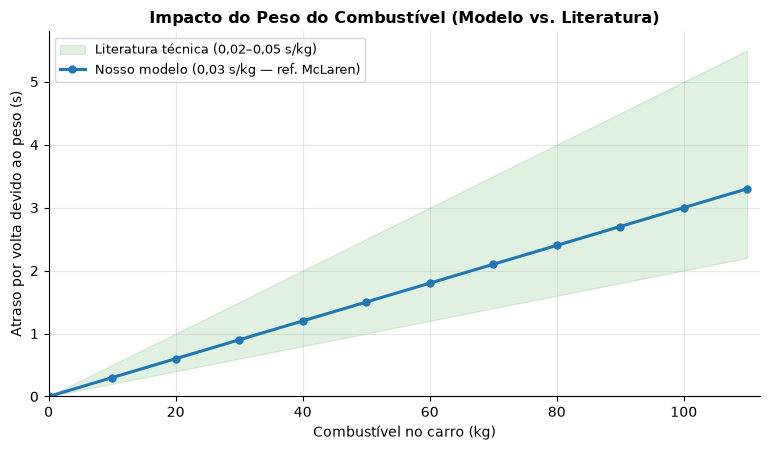

Delta por 10 kg: 0.30 s


In [4]:
fuel_levels = np.arange(0, 111, 10)
deltas = [fuel_time_delta(m) for m in fuel_levels]

fig, ax = plt.subplots(figsize=(7.8, 4.6))
ax.fill_between(
    fuel_levels,
    0.02 * fuel_levels,
    0.05 * fuel_levels,
    color="tab:green",
    alpha=0.14,
    label="Literatura técnica (0,02–0,05 s/kg)",
)
ax.plot(
    fuel_levels,
    deltas,
    marker="o",
    markersize=5,
    color="tab:blue",
    lw=2.2,
    label="Nosso modelo (0,03 s/kg — ref. McLaren)",
)
ax.set_title("Impacto do Peso do Combustível (Modelo vs. Literatura)", fontsize=11.5, fontweight="bold")
ax.set_xlabel("Combustível no carro (kg)", fontsize=10)
ax.set_ylabel("Atraso por volta devido ao peso (s)", fontsize=10)
ax.set_xlim(0, 112)
ax.set_ylim(0, 5.8)
ax.grid(alpha=0.3)
ax.legend(loc="upper left", fontsize=9, frameon=True)

plt.tight_layout()
plt.savefig("validacao_combustivel.png", dpi=130, bbox_inches="tight")
plt.show()

delta_10kg = fuel_time_delta(10) - fuel_time_delta(0)
print(f"Delta por 10 kg: {delta_10kg:.2f} s")
assert 0.2 <= delta_10kg <= 0.5


## 4. Qual pneu usar em cada clima? (Custo do pneu errado)

**Pergunta que este gráfico responde:** *Quanto tempo por volta um carro perde se estiver com o pneu errado para a condição da pista?*
- Em **Pista Seca**, os 3 pneus secos têm atraso `0,0 s` (linha de base ideal).
- Em **Pista Úmida**, o **Intermediário** passa a ser o melhor (`+1,2 s`).
- Em **Chuva Forte**, apenas o **Chuva Pesada (`+3,0 s`, ref. literatura)** é viável; pneus secos perdem ~20 s por volta.

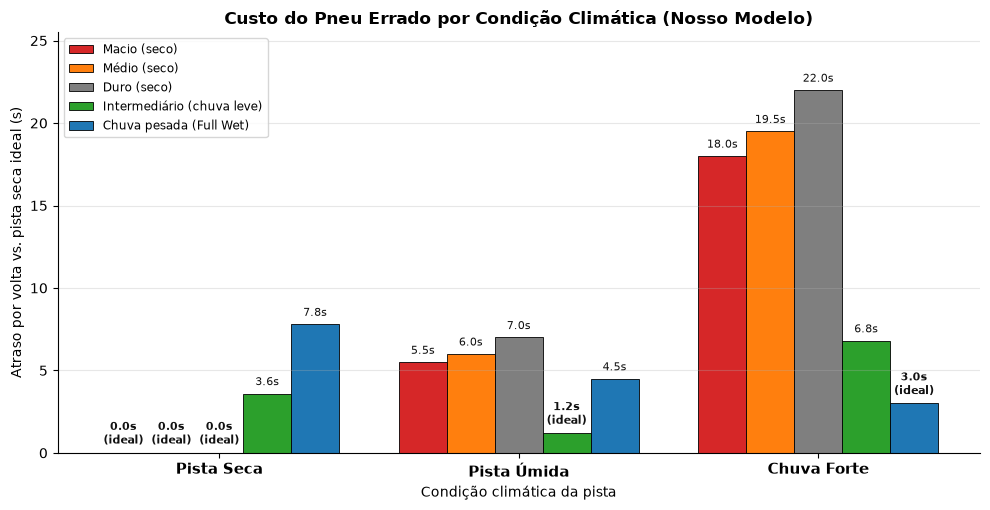

In [5]:
weather_states = ["seco", "umido", "molhado"]
weather_labels = ["Pista Seca", "Pista Úmida", "Chuva Forte"]
comp_palette = [
    ("soft", "Macio (seco)", "#d62728"),
    ("medium", "Médio (seco)", "#ff7f0e"),
    ("hard", "Duro (seco)", "#7f7f7f"),
    ("intermediate", "Intermediário (chuva leve)", "#2ca02c"),
    ("wet", "Chuva pesada (Full Wet)", "#1f77b4"),
]

# Composto ótimo em cada condição (para destacar no gráfico)
best_by_state = {
    "seco": {"soft", "medium", "hard"},
    "umido": {"intermediate"},
    "molhado": {"wet"},
}

fig, ax = plt.subplots(figsize=(10.0, 5.2))
x = np.arange(len(weather_states))
width = 0.16

for i, (comp, lbl, col) in enumerate(comp_palette):
    deltas_clima = [weather_time_delta(comp, ws) for ws in weather_states]
    offset = (i - 2) * width
    bars = ax.bar(
        x + offset,
        deltas_clima,
        width,
        label=lbl,
        color=col,
        edgecolor="black",
        linewidth=0.6,
    )
    for ws_idx, (b, val) in enumerate(zip(bars, deltas_clima)):
        ws_key = weather_states[ws_idx]
        is_best = comp in best_by_state[ws_key]
        txt = f"{val:.1f}s\n(ideal)" if is_best else f"{val:.1f}s"
        ax.text(
            b.get_x() + b.get_width() / 2,
            val + 0.35,
            txt,
            ha="center",
            va="bottom",
            fontsize=7.6 if is_best else 7.8,
            fontweight="bold" if is_best else "normal",
            color="#111111",
        )

ax.set_xticks(x)
ax.set_xticklabels(weather_labels, fontsize=10.5, fontweight="bold")
ax.set_xlabel("Condição climática da pista", fontsize=10)
ax.set_ylabel("Atraso por volta vs. pista seca ideal (s)", fontsize=10)
ax.set_title("Custo do Pneu Errado por Condição Climática (Nosso Modelo)", fontsize=12, fontweight="bold")
ax.set_ylim(0, 25.5)
ax.grid(axis="y", alpha=0.3)
ax.legend(fontsize=8.8, loc="upper left", frameon=True)

plt.tight_layout()
plt.savefig("validacao_clima_crossover.png", dpi=130, bbox_inches="tight")
plt.show()


## 5. Evolução das Probabilidades do Clima — Cadeia de Markov ($\pi_n = \pi_0 \cdot P^n$)

**Pergunta que este gráfico responde:** *Se a corrida larga com 100% de certeza de pista seca ($\pi_0 = [1,\; 0,\; 0]$), como evoluem as probabilidades de pista seca, úmida e chuva forte a cada volta $n$ pela potência da matriz $\pi_n = \pi_0 \cdot P^n$?*

Volta  0: Seca = 100.0% | Úmida =   0.0% | Chuva Forte =   0.0%
Volta  1: Seca =  95.0% | Úmida =   4.0% | Chuva Forte =   1.0%
Volta  2: Seca =  91.1% | Úmida =   6.6% | Chuva Forte =   2.3%
Volta  5: Seca =  83.1% | Úmida =  10.9% | Chuva Forte =   6.0%
Volta 10: Seca =  76.3% | Úmida =  14.1% | Chuva Forte =   9.7%
Volta 20: Seca =  71.9% | Úmida =  16.0% | Chuva Forte =  12.1%
Volta 58: Seca =  70.9% | Úmida =  16.4% | Chuva Forte =  12.7%


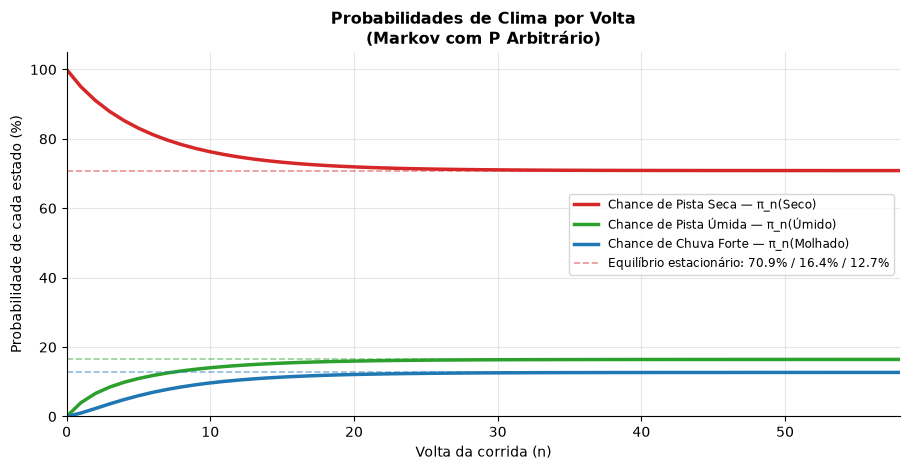

In [6]:
from sim.weather import DEFAULT_TRANSITION_PROBABILITIES

states = ["seco", "umido", "molhado"]
P = np.array([[DEFAULT_TRANSITION_PROBABILITIES[s1][s2] for s2 in states] for s1 in states])
pi_0 = np.array([1.0, 0.0, 0.0])  # Largada: 100% Pista Seca

laps = np.arange(0, 59)
probs = np.array([pi_0 @ np.linalg.matrix_power(P, int(n)) for n in laps]) * 100.0

for n in [0, 1, 2, 5, 10, 20, 58]:
    p_s, p_u, p_m = probs[n]
    print(f"Volta {n:2d}: Seca = {p_s:5.1f}% | Úmida = {p_u:5.1f}% | Chuva Forte = {p_m:5.1f}%")

fig, ax = plt.subplots(figsize=(9.2, 4.8))
ax.plot(laps, probs[:, 0], lw=2.5, color="#d62728", label="Chance de Pista Seca — π_n(Seco)")
ax.plot(laps, probs[:, 1], lw=2.5, color="#2ca02c", label="Chance de Pista Úmida — π_n(Úmido)")
ax.plot(laps, probs[:, 2], lw=2.5, color="#1f77b4", label="Chance de Chuva Forte — π_n(Molhado)")

# Linhas tracejadas do equilíbrio estacionário (n -> infinito)
pi_inf = (pi_0 @ np.linalg.matrix_power(P, 500)) * 100.0
ax.axhline(pi_inf[0], color="#d62728", ls="--", alpha=0.5, lw=1.2, label=f"Equilíbrio estacionário: {pi_inf[0]:.1f}% / {pi_inf[1]:.1f}% / {pi_inf[2]:.1f}%")
ax.axhline(pi_inf[1], color="#2ca02c", ls="--", alpha=0.5, lw=1.2)
ax.axhline(pi_inf[2], color="#1f77b4", ls="--", alpha=0.5, lw=1.2)

ax.set_xlim(0, 58)
ax.set_ylim(0, 105)
ax.set_xlabel("Volta da corrida (n)", fontsize=10)
ax.set_ylabel("Probabilidade de cada estado (%)", fontsize=10)
ax.set_title("Probabilidades de Clima por Volta\n(Markov com P Arbitrário)", fontsize=11.5, fontweight="bold")
ax.grid(alpha=0.3)
ax.legend(loc="center right", fontsize=8.8, frameon=True)

plt.tight_layout()
plt.savefig("validacao_clima_markov.png", dpi=130, bbox_inches="tight")
plt.show()
